In [ ]:
## AVIRIS-NG based band-ratio optimization for LAI modeling in low-stature shrubland vegetation.
## Author: Ramesh Bhatta, RIT
## Contact: rb1005@rit.edu

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import pandas as pd
import folium
import os
import rasterio
from rasterio.mask import mask
import geopandas as gpd
from netCDF4 import Dataset
from shapely.geometry import box
from scipy.stats import linregress

In [ ]:
## A. Load the data

# Define file paths
shapefile_path = "./ground_LAI_data_processed/5mx5m_LAI_plots.shp"
raster_files = [
    "./AVIRIS_NG_data/ang20231031t092656_002_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc",
    "./AVIRIS_NG_data/ang20231109t062226_001_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc", # Download these file from the AVIRIS-NG data portal or ORNL DAAC portal
    "./AVIRIS_NG_data/ang20231109t062226_002_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc",
    "./AVIRIS_NG_data/ang20231117t123306_001_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc"
]

# Load shapefile
print("Loading ground truth shapefile...")
gdf = gpd.read_file(shapefile_path)

# Print the dataframe
gdf

Loading ground truth shapefile...


,plot_id,LAI_mean,LAI_sd,n_reps,lon_mean,lat_mean,geometry
0,GBS0619,2.112576,0.371472,3,19.417133,-34.531937,"POLYGON ((354738.981 6177726.267, 354738.981 6..."
1,GBS0622,2.348314,0.658946,3,19.416763,-34.532163,"POLYGON ((354705.416 6177700.597, 354705.416 6..."
2,GBS0625,1.575255,0.150760,3,19.416767,-34.531720,"POLYGON ((354704.952 6177749.769, 354704.952 6..."
3,GBS0626,1.790895,0.190132,3,19.417487,-34.532730,"POLYGON ((354772.788 6177638.792, 354772.788 6..."
4,GBS0627,1.413221,0.461606,3,19.416707,-34.532463,"POLYGON ((354700.736 6177667.245, 354700.736 6..."
5,GBS06P,1.977499,0.464075,2,19.417480,-34.531775,"POLYGON ((354770.518 6177744.695, 354770.518 6..."
6,GBS161,1.603689,0.088037,3,19.433223,-34.522277,"POLYGON ((356199.124 6178820.6, 356199.124 617..."
7,GBS162,2.146058,0.625778,3,19.432560,-34.523790,"POLYGON ((356140.839 6178651.824, 356140.839 6..."
8,GBS164,1.737210,0.462670,3,19.432193,-34.522473,"POLYGON ((356104.917 6178797.323, 356104.917 6..."
9,GBS168,1.622965,0.323063,3,19.431970,-34.523577,"POLYGON ((356086.316 6178674.643, 356086.316 6..."


In [3]:
## Check the coordinate reference system (CRS) of the shapefile.

gdf.crs

<Projected CRS: EPSG:32734>
Name: WGS 84 / UTM zone 34S
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 18°E and 24°E, southern hemisphere between 80°S and equator, onshore and offshore. Angola. Botswana. Democratic Republic of the Congo (Zaire). Namibia. South Africa. Zambia.
- bounds: (18.0, -80.0, 24.0, 0.0)
Coordinate Operation:
- name: UTM zone 34S
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [4]:
## B. Visualize the data 

"""
Ensure the shapefile is in WGS84 (Lat/Lon) for Folium visualization library.
If the shapefile has no CRS defined, we assume it matches the Rasters.
But usually, shapefiles have a CRS. We convert to EPSG:4326 for the map.
"""

# Calculate centroids in projected CRS
centroids_proj = gdf.geometry.centroid

# Convert centroids to WGS84 for Folium
centroids_wgs84 = gpd.GeoSeries(centroids_proj, crs="EPSG:32734").to_crs("EPSG:4326")
gdf_map = gdf.copy()
gdf_map.geometry = centroids_wgs84

# Get mean lat/lon for map center
center_lat = centroids_wgs84.y.mean()
center_lon = centroids_wgs84.x.mean()

m = folium.Map(location=[center_lat, center_lon], zoom_start=14, tiles='Esri.WorldImagery')

# Add Plots to Map 
# (Blue Markers)
for idx, row in gdf_map.iterrows():
    folium.Marker(
        location=[row.geometry.centroid.y, row.geometry.centroid.x],
        popup=f"Plot ID: {row.get('plot_id', idx)}",
        icon=folium.Icon(color='blue', icon='leaf')
    ).add_to(m)

# Add Raster Bounds to Map
print("Processing AVIRIS Imagery...")

for r_file in raster_files:
    netcdf_path = f"NETCDF:{r_file}:/reflectance/reflectance"
    
    if not os.path.exists(r_file):
        # Try checking if file is in current dir just in case
        if os.path.exists(os.path.basename(r_file)):
             netcdf_path = f"NETCDF:{os.path.basename(r_file)}:/reflectance/reflectance"
        else:
            print(f"  [MISSING] File not found: {r_file}")
            continue

    try:
        with rasterio.open(netcdf_path) as src:
            # 1. Get the bounding box of the raster
            bounds = src.bounds
            geom = box(bounds.left, bounds.bottom, bounds.right, bounds.top)
            
            # 2. Create a GeoDataFrame for this single footprint
            gdf_footprint = gpd.GeoDataFrame({"geometry": [geom]}, crs=src.crs)
            
            # 3. Reproject to WGS84 for the map
            gdf_footprint = gdf_footprint.to_crs("EPSG:4326")
            
            # 4. Add to Folium Map 
            # (Red Polygons)
            folium.GeoJson(
                gdf_footprint,
                name=os.path.basename(r_file),
                style_function=lambda x: {'color': 'red', 'fillOpacity': 0.1, 'weight': 2},
                tooltip=f"Image: {os.path.basename(r_file)}"
            ).add_to(m)
            
            print(f"  [SUCCESS] Added footprint for {os.path.basename(r_file)}")
            
    except Exception as e:
        print(f"  [ERROR] Could not read {os.path.basename(r_file)}: {e}")

# Display the map
print("\nMap Generated. Blue = Plots, Red = Image Extents.")
m

Processing AVIRIS Imagery...
  [SUCCESS] Added footprint for ang20231031t092656_002_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc
  [SUCCESS] Added footprint for ang20231109t062226_001_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc
  [SUCCESS] Added footprint for ang20231109t062226_002_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc
  [SUCCESS] Added footprint for ang20231117t123306_001_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc

Map Generated. Blue = Plots, Red = Image Extents.


In [5]:
## C. Extract Hyperspectral data for each plot

# Create a dictionary to hold candidate spectra for each plot
candidates = {pid: [] for pid in gdf['plot_id'].unique()}
wavelengths = None

print(f"Starting Extraction for {len(gdf)} plots...")

# Main loop through raster files
for nc_file in raster_files:
    if os.path.exists(nc_file):
        actual_path = nc_file
    elif os.path.exists(os.path.basename(nc_file)):
        actual_path = os.path.basename(nc_file)
    else: continue

    netcdf_path = f"NETCDF:{actual_path}:/reflectance/reflectance"

    try:
        with rasterio.open(netcdf_path) as src:
            # 1. Capture wavelengths
            if wavelengths is None:
                with Dataset(actual_path, mode="r") as ds:
                    wavelengths = ds.groups["reflectance"].variables["wavelength"][:]

            # 2. Project plots to match raster CRS
            gdf_local = gdf.to_crs(src.crs)

            # 3. Iterate plots
            for idx, row in gdf_local.iterrows():
                geom = row.geometry
                bounds = src.bounds
                
                # Check if plot is within image extents
                if not box(bounds.left, bounds.bottom, bounds.right, bounds.top).intersects(geom):
                    continue

                try:
                    # ATTEMPT 1: Exact polygon mask
                    # all_touched=True ensures we grab pixels on the edges
                    out_image, _ = mask(src, [geom], crop=True, all_touched=True, nodata=-9999)
                    data = out_image.reshape(out_image.shape[0], -1)
                    
                    # Filter valid pixels (using band 100 as a check)
                    valid_mask = (data[100, :] > -50) 
                    valid_pixels = data[:, valid_mask]
                    
                    # ATTEMPT 2: Centroid fallback if no valid pixels from polygon
                    # If the polygon mask failed (0 pixels), grab the center pixel ONLY
                    if valid_pixels.shape[1] == 0:
                        cx, cy = geom.centroid.x, geom.centroid.y
                        r, c = src.index(cx, cy)
                        # Ensure centroid is inside the image grid
                        if 0 <= r < src.height and 0 <= c < src.width:
                            window = rasterio.windows.Window(c, r, 1, 1)
                            centroid_data = src.read(window=window).reshape(src.count, -1)
                            if np.all(centroid_data[100, :] > -50):
                                valid_pixels = centroid_data

                    # Save valid spectra if we have any
                    if valid_pixels.shape[1] > 0:
                        mean_spectrum = np.mean(valid_pixels, axis=1)
                        img_cx, img_cy = (bounds.left + bounds.right)/2, (bounds.top + bounds.bottom)/2
                        dist = np.sqrt((geom.centroid.x - img_cx)**2 + (geom.centroid.y - img_cy)**2)
                        
                        candidates[row['plot_id']].append({
                            'spectrum': mean_spectrum,
                            'dist': dist,
                            'file': os.path.basename(actual_path),
                            'pixels': valid_pixels.shape[1]
                        })
                        
                except Exception:
                    continue

    except Exception as e:
        print(f"  [ERROR] {os.path.basename(actual_path)}: {e}")

# Finalize records by picking the best spectrum for each plot
final_records = []
for pid, data_list in candidates.items():
    if not data_list:
        print(f"  [FAILED] Plot {pid}: No data found.")
        continue
    
    data_list.sort(key=lambda x: x['dist']) # Pick the nadir-most flightline
    best = data_list[0]
    
    rec = {
        'plot_id': pid, 'source_file': best['file'], 
        'dist_to_center': round(best['dist'], 1), 'pixels_used': best['pixels']
    }
    for i, val in enumerate(best['spectrum']):
        rec[f'band_{i}'] = val
    final_records.append(rec)

df_spectra = pd.DataFrame(final_records)
print(f"Extraction Complete: {len(df_spectra)} / {len(gdf)} plots.")

Starting Extraction for 20 plots...
Extraction Complete: 20 / 20 plots.


Plotting all spectral signatures...


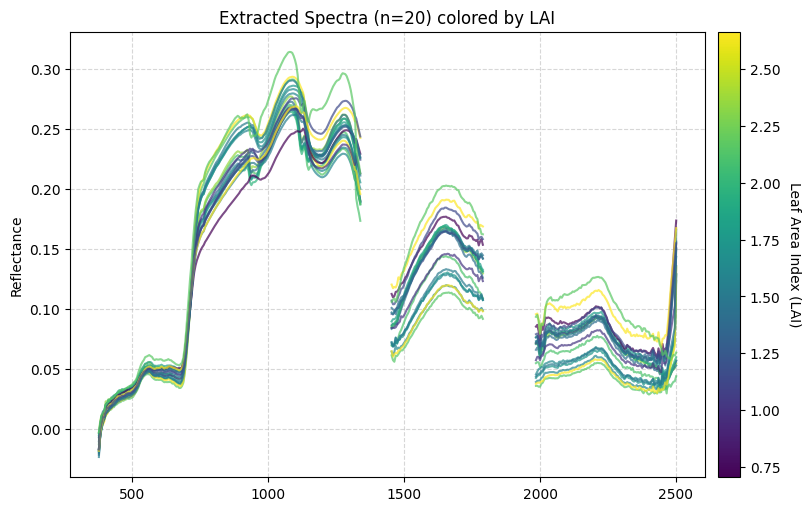

In [6]:
## D. Visualize the extracted spectra

# Ensure we have the LAI values attached to the spectra
plot_data = df_spectra.merge(gdf[['plot_id', 'LAI_mean']], on='plot_id', how='left')

# Extract just the band columns for plotting
band_cols = sorted([c for c in plot_data.columns if c.startswith('band_')], 
                   key=lambda x: int(x.split('_')[1]))

X_plot = plot_data[band_cols].values
lai_values = plot_data['LAI_mean'].values

# Plotting setup
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
norm = mcolors.Normalize(vmin=np.nanmin(lai_values), vmax=np.nanmax(lai_values)) # Color map based on LAI values
cmap = cm.viridis
print(f"Plotting all spectral signatures...")

for i in range(len(X_plot)):
    # Get spectrum and LAI
    spectrum = X_plot[i]
    lai = lai_values[i]
    
    # Mask out "bad" water absorption bands for cleaner plotting
    # Common AVIRIS-NG bad bands: ~1350-1420nm and ~1800-1950nm
    spectrum_masked = spectrum.copy()
    
    # Identify indices of water bands (approximate)
    bad_indices = np.where(
        ((wavelengths > 1340) & (wavelengths < 1450)) | 
        ((wavelengths > 1790) & (wavelengths < 1980))
    )[0]
    spectrum_masked[bad_indices] = np.nan
    
    # Plot line
    color = cmap(norm(lai))
    ax.plot(wavelengths, spectrum_masked, color=color, alpha=0.7, linewidth=1.5)
    target_wavelengths = [2005.0, 2320.6]
    for wl in target_wavelengths:
        idx = (np.abs(wavelengths - wl)).argmin()

# Add colorbar for LAI
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label('Leaf Area Index (LAI)', rotation=270, labelpad=15)
ax.set_title(f"Extracted Spectra (n={len(X_plot)}) colored by LAI")
ax.set_ylabel("Reflectance")
ax.set_label("Wavelength (nm)")
ax.grid(which = 'both', linestyle='--', alpha=0.5)
plt.show()

Optimizing across 425 bands.
Skipping dead/constant bands...
Processing band 0/425...
Processing band 50/425...
Processing band 100/425...
Processing band 150/425...
Processing band 200/425...
Processing band 250/425...
Processing band 300/425...
Processing band 350/425...
Processing band 400/425...
----------------------------------------------------------------------------------------------------
Optimization Complete
Best R² Achieved: 0.522
Best Wavelengths: 2005.0 nm and 2320.6 nm


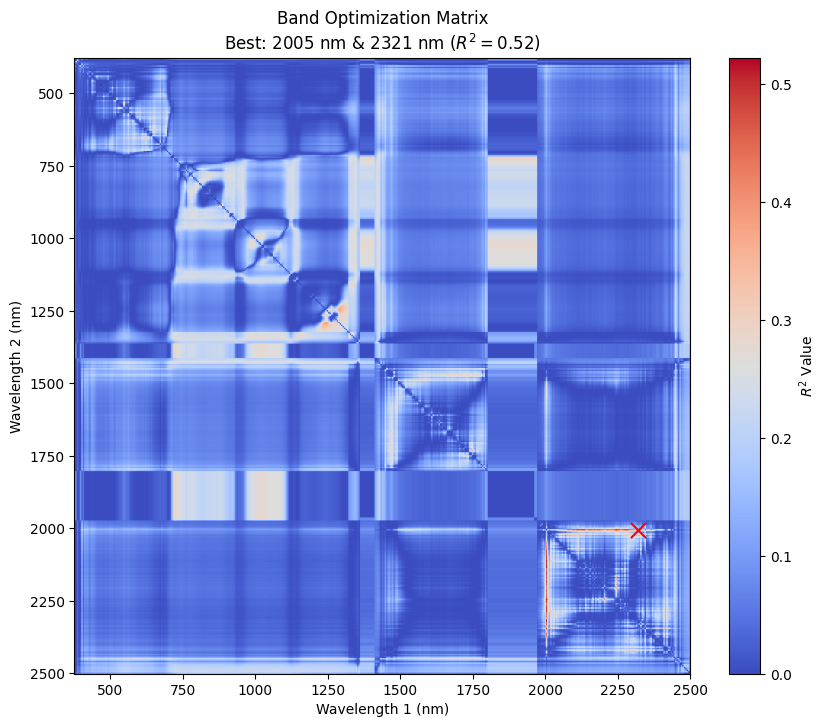

In [7]:
## E. (a) Robust Band-Ratio Optimization to Model LAI

# Prepare data by replacing NaNs with zeros
X_clean = np.nan_to_num(X_plot, nan=0.0)
n_bands = X_clean.shape[1]
best_r2 = 0
best_bands = (0, 0)
best_index_values = np.zeros(len(lai_values))
best_wl = (0, 0)

# Matrix to store results
r2_matrix = np.zeros((n_bands, n_bands))

print(f"Optimizing across {n_bands} bands.\nSkipping dead/constant bands...")

# Robust optimization loop
for i in range(n_bands):
    # Progress indicator every 50 bands
    if i % 50 == 0: print(f"Processing band {i}/{n_bands}...")
        
    for j in range(i + 1, n_bands): # Upper triangle only
        
        b1 = X_clean[:, i]
        b2 = X_clean[:, j]
        
        # SAFETY CHECK 1: Skip if bands are all zeros (masked water bands)
        if np.all(b1 == 0) or np.all(b2 == 0):
            continue
            
        # Calculate Index
        # (B2 - B1) / (B2 + B1)
        denominator = b2 + b1 + 1e-6
        custom_index = (b2 - b1) / denominator
        
        # SAFETY CHECK 2: Check for variance
        # If all plots have the exact same index value, linregress can crash.
        if np.std(custom_index) < 1e-9:
            continue
            
        try:
            # Correlate
            slope, intercept, r_val, p_val, std_err = linregress(custom_index, lai_values)
            
            # Store R2 (Handle NaNs as well)
            if np.isfinite(r_val):
                current_r2 = r_val**2
            else:
                current_r2 = 0
            
            r2_matrix[i, j] = current_r2
            r2_matrix[j, i] = current_r2 # Symmetric
            
            # Update best if improved
            if current_r2 > best_r2:
                best_r2 = current_r2
                best_bands = (i, j)
                best_index_values = custom_index
                best_wl = (wavelengths[i], wavelengths[j])
                
        except Exception as e:
            continue

# Report the results and visualize the R² matrix
print("--" * 50)
print(f"Optimization Complete")
if best_r2 > 0:
    print(f"Best R² Achieved: {best_r2:.3f}")
    print(f"Best Wavelengths: {best_wl[0]:.1f} nm and {best_wl[1]:.1f} nm")
    
    plt.figure(figsize=(10, 8))
    plt.imshow(r2_matrix, extent=[wavelengths.min(), wavelengths.max(), wavelengths.max(), wavelengths.min()], 
               origin='upper', cmap='coolwarm')
    plt.colorbar(label='$R^2$ Value')
    plt.title(f"Band Optimization Matrix\nBest: {best_wl[0]:.0f} nm & {best_wl[1]:.0f} nm ($R^2={best_r2:.2f}$)")
    plt.xlabel("Wavelength 1 (nm)")
    plt.ylabel("Wavelength 2 (nm)")
    plt.scatter([best_wl[1]], [best_wl[0]], color='red', s=120, marker='x')
    plt.show()
else:
    print("No valid correlations found. Check if X_clean contains valid data.")

In [9]:
## E.II. Top 'n' wavelength combinations.

n = 100  # Number of top combinations to display
r2_threshold = 0.30 # performance better than R² of 0.30

results_list = []

print(f"Searching for Top {n} combinations.")

for i in range(n_bands):
    if i % 50 == 0: print(f"  Processing band {i}/{n_bands}...")
        
    for j in range(i + 1, n_bands):
        b1, b2 = X_clean[:, i], X_clean[:, j]
        
        if np.all(b1 == 0) or np.all(b2 == 0): continue
            
        denominator = b2 + b1 + 1e-6
        custom_index = (b2 - b1) / denominator
        
        if np.std(custom_index) < 1e-9: continue
            
        try:
            slope, intercept, r_val, p_val, std_err = linregress(custom_index, lai_values)
            current_r2 = r_val**2 if np.isfinite(r_val) else 0
            
            r2_matrix[i, j] = current_r2
            r2_matrix[j, i] = current_r2
            
            if current_r2 > r2_threshold:
                results_list.append({
                    'Band_i_idx': i,
                    'Band_j_idx': j,
                    'Wavelength_i': wavelengths[i],
                    'Wavelength_j': wavelengths[j],
                    'R2': current_r2,
                    'p_val': p_val
                })
        except:
            continue

# Create a DataFrame of results and sort by R²
df_all_winners = pd.DataFrame(results_list).sort_values(by='R2', ascending=False)

# Display the top 'n' combinations
top_n_df = df_all_winners.head(20)
print("\n" + "="*80)
print(f"{'TOP ' + str(n) + ' BAND COMBINATIONS':^80}")
print("="*80)
print(top_n_df[['Wavelength_i', 'Wavelength_j', 'R2', 'p_val']].to_string(index=False))
print("="*80)

Searching for Top 100 combinations.
  Processing band 0/425...
  Processing band 50/425...
  Processing band 100/425...
  Processing band 150/425...
  Processing band 200/425...
  Processing band 250/425...
  Processing band 300/425...
  Processing band 350/425...
  Processing band 400/425...

                           TOP 100 BAND COMBINATIONS                            
 Wavelength_i  Wavelength_j       R2    p_val
  2005.015625   2320.555664 0.522080 0.000320
  2005.015625   2110.195557 0.511771 0.000391
  2005.015625   2135.235596 0.508401 0.000417
  2005.015625   2130.225586 0.502603 0.000466
  2005.015625   2125.225586 0.500262 0.000487
  2005.015625   2100.175537 0.498948 0.000499
  2005.015625   2245.425537 0.496728 0.000521
  2005.015625   2115.205566 0.494815 0.000540
  2005.015625   2345.605713 0.492691 0.000561
  2005.015625   2285.495605 0.492516 0.000563
  2005.015625   2255.445557 0.492045 0.000568
  2005.015625   2120.215576 0.488924 0.000602
  2005.015625   2275.48559

#### **COMMENTS**

#### **Multi-Domain Spectral Sensitivity: Top Regional Performers for LAI**

The optimization of band combinations (Normalized Difference Indices) revealed four distinct spectral domains where $R^{2} > 0.35$. This diversity confirms that our model captures a comprehensive "biophysical profile" of the Fynbos canopy.

| Spectral Domain | Wavelength Pair (nm) | $R^{2}$ | Biophysical Mechanism |
|:---|:---:|:---:|:---|
| **Primary SWIR** | 2005.0 & 2320.5 | **0.522** | **Carbon Bulk:** Sensitive to lignocellulose and woody structural biomass. |
| **NIR Plateau** | 1243.6 & 1288.7 | **0.377** | **Canopy Layering:** Responds to leaf mesophyll scattering and air-cell interfaces. |
| **Visible Range** | 527.4 & 547.4 | **0.365** | **Photosynthetic Capacity:** Captures chlorophyll-a/b activity in the green peak. |
| **SWIR-1 Bridge** | 1729.5 & 1749.5 | **0.354** | **Canopy Chemistry:** Associated with leaf proteins, nitrogen, and wax coatings. |

* **Structural Dominance:** The superior performance of the **Primary SWIR** region (2.0–2.3 μm) suggests that in fire-driven low-stature vegetation like Fynbos, the "woodiness" and dry-matter bulk are more reliable predictors of LAI than traditional "greenness."
* **Information Redundancy:** The high $R^{2}$ values across multiple regions (Top 100 results) indicate that these signals are complementary. While the SWIR is the strongest "anchor," the secondary NIR and Visible signals provide validation for leaf-level physiology.
* **Physical Validity:** The selection of **2320.5 nm** is particularly significant as it aligns with the known cellulose absorption feature, providing a direct physical link between our hyperspectral index and the plant's structural fibers.

---




                                 INDEX RANKING                                  
                 Index Category       R2     RMSE    p_val
       GBS_Custom_SWIR     SWIR 0.522079 0.354831 0.000320
    Compound_SWIR_NDVI     SWIR 0.489928 0.366572 0.000591
    Compound_SWIR_SAVI     SWIR 0.455746 0.378655 0.001091
   CAI (Cellulose Abs)     SWIR 0.447613 0.381474 0.001257
                   EVI     VNIR 0.168158 0.468127 0.072535
 NDNI (Nitrogen Index)     SWIR 0.164843 0.469059 0.075694
                  VARI     VNIR 0.164509 0.469153 0.076020
          SAVI (L=0.5)     VNIR 0.151222 0.472868 0.090158
MSR (Mod Simple Ratio)     VNIR 0.087940 0.490179 0.204230
     NDVI (Narrowband)     VNIR 0.082956 0.491517 0.218160
                NDRE 2     VNIR 0.082486 0.491643 0.219530
           CI Red Edge Red Edge 0.076521 0.493238 0.237738
                  NDRE     VNIR 0.073361 0.494081 0.248073
            NDWI (Gao)     SWIR 0.066184 0.495991 0.273518
       NDII (Infrared)     VNIR 0

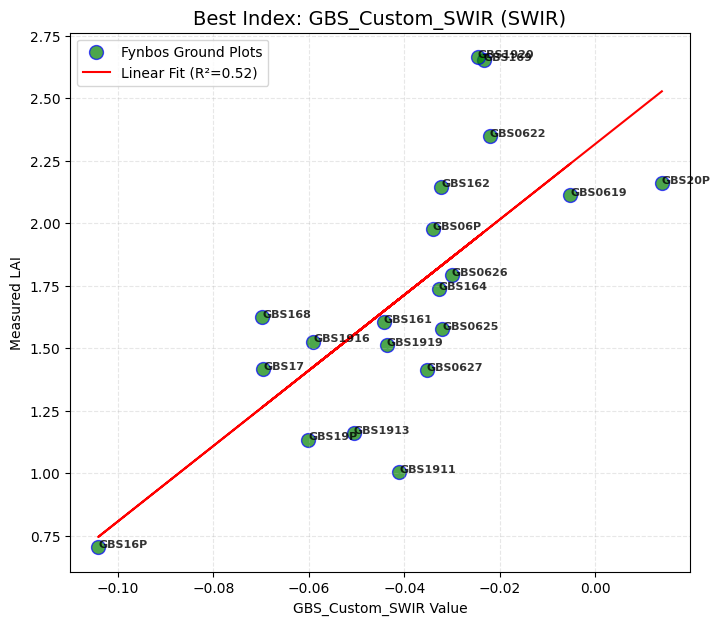

In [ ]:
## F. Simple Evaluation and comparison with literature based indices

# Helper function: Find the closed band/wavelength
def get_band(target_nm, wave_array, spectra_matrix):
    idx = np.argmin(np.abs(wave_array - target_nm))
    return spectra_matrix[:, idx]

# Extract all required bands in different regions of the spectrum to calculate indices

# 1. Visible
b_480 = get_band(480, wavelengths, X_plot)  # Blue
b_515 = get_band(515, wavelengths, X_plot)  # Carotenoid
b_531 = get_band(531, wavelengths, X_plot)  # PRI 1
b_550 = get_band(550, wavelengths, X_plot)  # Green
b_570 = get_band(570, wavelengths, X_plot)  # PRI 2
b_670 = get_band(670, wavelengths, X_plot)  # Red
b_681 = get_band(681, wavelengths, X_plot)  # Red absorption pit

# 2. Red Edge
b_700 = get_band(700, wavelengths, X_plot)
b_705 = get_band(705, wavelengths, X_plot)
b_709 = get_band(709, wavelengths, X_plot)
b_720 = get_band(720, wavelengths, X_plot)
b_740 = get_band(740, wavelengths, X_plot)
b_754 = get_band(754, wavelengths, X_plot)

# 3. NIR & SWIR 1 (Water)
b_800 = get_band(800, wavelengths, X_plot)
b_850 = get_band(850, wavelengths, X_plot)
b_860 = get_band(860, wavelengths, X_plot)
b_1240 = get_band(1240, wavelengths, X_plot)
b_1510 = get_band(1510, wavelengths, X_plot) # Nitrogen
b_1600 = get_band(1600, wavelengths, X_plot)
b_1680 = get_band(1680, wavelengths, X_plot) # Nitrogen / Lignin reference

# 4. SWIR 2 (Lignin/Cellulose/Dry Matter)
b_1750 = get_band(1750, wavelengths, X_plot)
b_2005 = get_band(2005, wavelengths, X_plot)
b_2100 = get_band(2100, wavelengths, X_plot)
b_2210 = get_band(2210, wavelengths, X_plot)
b_2320 = get_band(2320, wavelengths, X_plot)

# Calculate comprehensive set of indices
indices = {
    # 1. Greenness & pigments (VNIR): Range = 400-850nm
    "NDVI (Narrowband)": (b_850 - b_670) / (b_850 + b_670),
    "SAVI (L=0.5)": ((b_850 - b_670) / (b_850 + b_670 + 0.5)) * 1.5,
    "EVI": 2.5 * ((b_850 - b_670) / (b_850 + 6 * b_670 - 7.5 * b_480 + 1)),
    "GNDVI": (b_850 - b_550) / (b_850 + b_550),
    "VARI": (b_550 - b_670) / (b_550 + b_670 - b_480),
    "PRI (Physiology)": (b_531 - b_570) / (b_531 + b_570),
    "CRI (Carotenoid)": (1/b_515) - (1/b_550),

    # 2. Red-edge (Canopy Structure/Vigor): Range = 700-850nm
    "NDRE": (b_850 - b_720) / (b_850 + b_720),
    "CI Red Edge": (b_850 / b_720) - 1,
    "MTCI": (b_754 - b_709) / (b_709 - b_681),
    "NDVIre": (b_740 - b_705) / (b_740 + b_705), # Red Edge NDVI
    "MSR (Mod Simple Ratio)": (b_850 / b_670 - 1) / (np.sqrt(b_850 / b_670) + 1),

    # 3. Canopy water (SWIR 1): Range = 850-1600nm
    "NDWI (Gao)": (b_860 - b_1240) / (b_860 + b_1240),
    "MSI (Moisture Stress)": b_1600 / b_860,
    "NDII (Infrared)": (b_850 - b_1600) / (b_850 + b_1600),

    # 4. Structural & Dry matter (SWIR 2): Range = 1700-2500nm
    "CAI (Cellulose Abs)": 0.5 * (b_2005 + b_2210) - b_2100,
    "NDLI (Lignin Index)": (np.log(1/b_1750) - np.log(1/b_1680)) / (np.log(1/b_1750) + np.log(1/b_1680)),
    "NDNI (Nitrogen Index)": (np.log(1/b_1510) - np.log(1/b_1680)) / (np.log(1/b_1510) + np.log(1/b_1680)),
    "GBS_Custom_SWIR": (b_2320 - b_2005) / (b_2320 + b_2005), # Identified best

    # 5. Compound Indices
    "Compound_SWIR_NDVI": ((b_2320 - b_2005) / (b_2320 + b_2005)) * ((b_850 - b_670) / (b_850 + b_670)),
    "Compound_SWIR_SAVI": ((b_2320 - b_2005) / (b_2320 + b_2005)) * (((b_850 - b_670) / (b_850 + b_670 + 0.5)) * 1.5)
}

# Performance Evaluation
results_list = []

for name, values in indices.items():
    mask = ~np.isnan(values) & ~np.isnan(lai_values)
    slope, intercept, r_val, p_val, std_err = linregress(values[mask], lai_values[mask])
    
    r2 = r_val**2
    y_pred = slope * values + intercept
    rmse = np.sqrt(np.mean((lai_values - y_pred)**2))
    
    # Categorize for analysis
    category = "VNIR"
    if any(x in name.lower() for x in ['edge', 'mtci']): category = "Red Edge"
    elif any(x in name.lower() for x in ['swir', 'ndli', 'cai', 'ndwi', 'msi', 'ndni']): category = "SWIR"

    results_list.append({
        'Index': name, 'Category': category, 'R2': r2, 'RMSE': rmse, 'p_val': p_val
    })

df_results = pd.DataFrame(results_list).sort_values(by='R2', ascending=False)

# Output table of results
print("\n" + "="*75)
print(f"{'INDEX RANKING':^80}")
print("="*75)
print(df_results.to_string(index=False))
print("="*75)

# Choose best Index for plotting
best_row = df_results.iloc[0]
best_x = indices[best_row['Index']]
slope, intercept, _, _, _ = linregress(best_x, lai_values)
best_y_pred = slope * best_x + intercept

# Visualize the best performing index against LAI
plt.figure(figsize=(8, 7))
plt.scatter(best_x, lai_values, color='green', s=100, alpha=0.7, edgecolors='blue', label='Fynbos Ground Plots')
plt.plot(best_x, best_y_pred, color='red', linestyle='-', label=f"Linear Fit (R²={best_row['R2']:.2f})")
# Add plot_id labels for for each point
for i, plot_id in enumerate(plot_data['plot_id']):
    plt.text(best_x[i], lai_values[i], str(plot_id), fontsize=8, weight="bold", alpha=0.8)
plt.title(f"Best Index: {best_row['Index']} ({best_row['Category']})", fontsize=14)
plt.xlabel(f"{best_row['Index']} Value")
plt.ylabel("Measured LAI")
plt.legend()
plt.grid(True,linestyle='--', alpha=0.3)
plt.show()